<a href="https://colab.research.google.com/github/andarahabibie/DataScienceToolsEcosystem/blob/main/Mapping_Global_Prosperity_and_Well_Being_(2025).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd

# File paths
gdp_file = "/content/GDP per Capita 2025.csv"
happiness_file = "/content/happiest-countries-in-the-world-2025.csv"

# Load the datasets
gdp_df = pd.read_csv(gdp_file)
happiness_df = pd.read_csv(happiness_file)

# Display the first few rows of each dataset
gdp_df.head(), happiness_df.head()


(                  Country Name  GDP per Capita
 0                        Aruba    33984.790620
 1  Africa Eastern and Southern     1659.515290
 2                  Afghanistan      415.707417
 3   Africa Western and Central     1568.724310
 4                       Angola     2308.159767,
    country HappiestCountriesWorldHappinessReportScore2025
 0  Finland                                           7.74
 1  Denmark                                           7.58
 2  Iceland                                           7.53
 3   Sweden                                           7.34
 4   Israel                                           7.34)

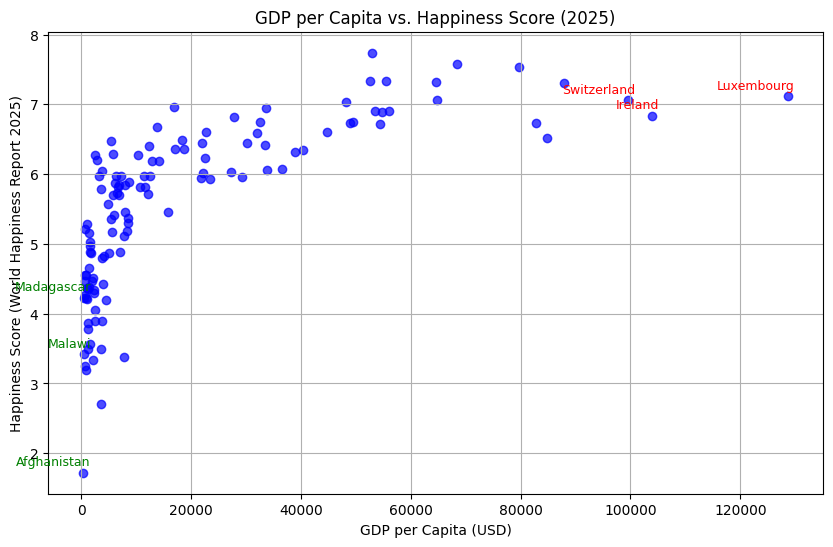

'gdp_vs_happiness.png'

In [ ]:
import matplotlib.pyplot as plt

# Merge datasets on country names
merged_df = pd.merge(
    happiness_df, gdp_df,
    left_on="country", right_on="Country Name",
    how="inner"
).drop(columns=["Country Name"])

# Convert happiness scores to numeric values
merged_df["Happiness Score"] = pd.to_numeric(
    merged_df["HappiestCountriesWorldHappinessReportScore2025"], errors='coerce'
)

# Sort data by GDP per capita for better visualization
merged_df = merged_df.sort_values(by="GDP per Capita")

# Create scatter plot
plt.figure(figsize=(10, 6))
plt.scatter(merged_df["GDP per Capita"], merged_df["Happiness Score"], alpha=0.7, color="blue")

# Labeling key points (highest and lowest GDP per capita)
for idx in merged_df.nlargest(3, "GDP per Capita").index:
    plt.annotate(merged_df.loc[idx, "country"],
                 (merged_df.loc[idx, "GDP per Capita"], merged_df.loc[idx, "Happiness Score"]),
                 textcoords="offset points", xytext=(5,5), ha='right', fontsize=9, color='red')

for idx in merged_df.nsmallest(3, "GDP per Capita").index:
    plt.annotate(merged_df.loc[idx, "country"],
                 (merged_df.loc[idx, "GDP per Capita"], merged_df.loc[idx, "Happiness Score"]),
                 textcoords="offset points", xytext=(5,5), ha='right', fontsize=9, color='green')

# Labels and title
plt.xlabel("GDP per Capita (USD)")
plt.ylabel("Happiness Score (World Happiness Report 2025)")
plt.title("GDP per Capita vs. Happiness Score (2025)")
plt.grid(True)

# Save the plot
plot_path = "gdp_vs_happiness.png"
plt.savefig(plot_path)
plt.show()

# Return the saved plot path
plot_path
